# 01_cuDF / 02 — cuDF operations

The everyday DataFrame operations, on the GPU, side by side with pandas:

1. Setup and a synthetic retail dataset (orders, customers, products)
2. **GroupBy** — aggregations, multiple keys, `nunique`, `transform`
3. **Joins** — inner, left, semi and anti joins
4. **Sorting** — multi-key sorts, `nlargest`
5. **String operations** — regex search, extract, split, replace
6. **Window functions** — cumulative sums, `shift`, `rank`, rolling windows
7. A small end-to-end pipeline that runs unchanged on pandas and cuDF
8. Timing summary

**Hardware:** NVIDIA T4 (16 GB).

## 1. Setup

In [1]:
import time, statistics, random
import cudf, cupy as cp, numpy as np, pandas as pd
import matplotlib.pyplot as plt

props = cp.cuda.runtime.getDeviceProperties(0)
print(f"cuDF {cudf.__version__} | pandas {pd.__version__} | GPU {props['name'].decode()}")

cuDF 26.06.00 | pandas 2.2.3 | GPU Tesla T4


In [2]:
def gpu_sync():
    cp.cuda.Device().synchronize()

def timeit(fn, repeats=3, warmup=1):
    """Median wall time in seconds, with GPU synchronized before each stop."""
    for _ in range(warmup):
        fn(); gpu_sync()
    times = []
    for _ in range(repeats):
        gpu_sync()
        t0 = time.perf_counter()
        fn()
        gpu_sync()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

timings = {}

def compare(label, pandas_fn, cudf_fn, repeats=3):
    """Time the same operation in pandas and cuDF and record the result."""
    t_pd = timeit(pandas_fn, repeats=repeats, warmup=0)
    t_cu = timeit(cudf_fn, repeats=repeats, warmup=1)
    timings[label] = (t_pd, t_cu)
    print(f"{label:<30} pandas {t_pd * 1e3:9.1f} ms | cuDF {t_cu * 1e3:8.1f} ms | {t_pd / t_cu:6.1f}x")

### The dataset

- `orders` — 5M rows: who bought what, where, when, and how many
- `customers` — 200k rows: segment and city
- `products` — 2,000 rows: category, name and price

A few orders point at product IDs that are **not** in the catalog, so we can see what joins do with unmatched keys.

In [3]:
N_ORDERS    = 5_000_000
N_CUSTOMERS = 200_000
N_PRODUCTS  = 2_000
rng = cp.random.default_rng(0)

segments = cudf.Series(["Consumer", "Corporate", "Home Office", "Small Business"])
cities   = cudf.Series(["Hyderabad", "Bengaluru", "Pune", "Jaipur", "Chennai", "Delhi", "Mumbai", "Kolkata"])
customers = cudf.DataFrame({
    "customer_id": cp.arange(N_CUSTOMERS, dtype="int32"),
    "segment":     segments.take(rng.integers(0, len(segments), N_CUSTOMERS)).reset_index(drop=True),
    "city":        cities.take(rng.integers(0, len(cities), N_CUSTOMERS)).reset_index(drop=True),
})

random.seed(0)
categories = ["Electronics", "Grocery", "Clothing", "Home", "Sports", "Books"]
colors     = ["Red", "Blue", "Black", "White", "Green"]
sizes      = ["S", "M", "L", "XL"]
prod_cats  = [random.choice(categories) for _ in range(N_PRODUCTS)]
products = cudf.DataFrame({
    "product_id":   np.arange(N_PRODUCTS, dtype="int32"),
    "category":     prod_cats,
    "product_name": [f"{c[:4].upper()}-{i:04d} {random.choice(colors)} {random.choice(sizes)}"
                     for i, c in enumerate(prod_cats)],
    "unit_price":   np.round(np.random.default_rng(0).uniform(5, 500, N_PRODUCTS), 2),
})

start_s = np.datetime64("2026-01-01T00:00:00", "s").astype("int64")
orders = cudf.DataFrame({
    "order_id":    cp.arange(N_ORDERS, dtype="int64"),
    "customer_id": rng.integers(0, N_CUSTOMERS, N_ORDERS).astype("int32"),
    "product_id":  rng.integers(0, N_PRODUCTS + 20, N_ORDERS).astype("int32"),   # +20 = unknown products
    "store_id":    rng.integers(0, 50, N_ORDERS).astype("int16"),
    "quantity":    rng.integers(1, 10, N_ORDERS).astype("int16"),
    "ts":          cudf.Series(start_s + rng.integers(0, 180 * 86_400, N_ORDERS)).astype("datetime64[s]"),
})
orders["month"] = orders["ts"].dt.month

print(f"orders {len(orders):,} | customers {len(customers):,} | products {len(products):,}")
orders.head()

orders 5,000,000 | customers 200,000 | products 2,000


,order_id,customer_id,product_id,store_id,quantity,ts,month
0,0,99633,1269,24,8,2026-05-17 18:56:22,5
1,1,31038,1743,11,9,2026-03-20 01:01:07,3
2,2,13785,1629,15,3,2026-03-05 22:27:28,3
3,3,27801,777,41,6,2026-06-08 07:54:20,6
4,4,135564,1630,24,5,2026-03-26 00:57:10,3


In [4]:
products.head()

,product_id,category,product_name,unit_price
0,0,Home,HOME-0000 Blue L,320.30
1,1,Home,HOME-0001 Blue M,138.54
2,2,Electronics,ELEC-0002 Red L,25.28
3,3,Clothing,CLOT-0003 Blue S,13.18
4,4,Sports,SPOR-0004 White XL,407.57


In [5]:
# Same data in pandas, for comparison
orders_pd    = orders.to_pandas()
customers_pd = customers.to_pandas()
products_pd  = products.to_pandas()

## 2. GroupBy

The split-apply-combine pattern. On the GPU, cuDF hashes or sorts the keys in parallel and aggregates each group with one kernel.

In [6]:
orders.groupby("store_id")["quantity"].sum().sort_index().head()

store_id
0    499358
1    498573
2    500060
3    502205
4    498276
Name: quantity, dtype: int64

In [7]:
# Several aggregations at once
agg = orders.groupby("store_id").agg({"quantity": ["sum", "mean", "max"], "order_id": "count"})
agg.columns = ["_".join(c) for c in agg.columns]
agg.sort_index().head()

,quantity_sum,quantity_mean,quantity_max,order_id_count
store_id,,,,
0,499358,4.988990,9,100092
1,498573,4.992820,9,99858
2,500060,4.990320,9,100206
3,502205,5.014628,9,100148
4,498276,4.998004,9,99695


In [8]:
# Multiple keys
orders.groupby(["store_id", "month"])["quantity"].sum().sort_index().head(8)

store_id  month
0         1        86462
          2        77384
          3        85749
          4        83141
          5        85726
          6        80896
1         1        86544
          2        76966
Name: quantity, dtype: int64

In [9]:
# Distinct customers per store
orders.groupby("store_id")["customer_id"].nunique().sort_index().head()

store_id
0    78630
1    78606
2    78822
3    78790
4    78569
Name: customer_id, dtype: int32

In [10]:
# transform() returns one value per *row* (not per group): handy for "compare to the group average"
orders["store_avg_qty"] = orders.groupby("store_id")["quantity"].transform("mean")
orders[["store_id", "quantity", "store_avg_qty"]].head()

,store_id,quantity,store_avg_qty
0,24,8,5.013563
1,11,9,5.003936
2,15,3,4.993934
3,41,6,4.993599
4,24,5,5.013563


In [11]:
# Same answer as pandas?
g = orders.groupby("store_id")["quantity"].sum().sort_index().to_pandas()
p = orders_pd.groupby("store_id")["quantity"].sum().sort_index()
print("matches pandas:", np.array_equal(g.values, p.values))

matches pandas: True


In [12]:
compare("groupby sum (1 key)",
        lambda: orders_pd.groupby("store_id")["quantity"].sum(),
        lambda: orders.groupby("store_id")["quantity"].sum())
compare("groupby multi-agg (2 keys)",
        lambda: orders_pd.groupby(["store_id", "month"]).agg({"quantity": ["sum", "mean"], "order_id": "count"}),
        lambda: orders.groupby(["store_id", "month"]).agg({"quantity": ["sum", "mean"], "order_id": "count"}))
compare("groupby nunique",
        lambda: orders_pd.groupby("store_id")["customer_id"].nunique(),
        lambda: orders.groupby("store_id")["customer_id"].nunique())

groupby sum (1 key)            pandas     103.1 ms | cuDF      8.1 ms |   12.7x
groupby multi-agg (2 keys)     pandas     346.8 ms | cuDF     18.7 ms |   18.5x
groupby nunique                pandas     727.6 ms | cuDF    130.5 ms |    5.6x


## 3. Joins

`merge` works like pandas. Two cuDF differences to know:

- **Row order is not guaranteed.** GPU hash joins write rows in whatever order threads finish. Sort afterwards (or pass `sort=True`) if order matters.
- cuDF has native **semi** and **anti** joins: `how="leftsemi"` keeps left rows that have a match, `how="leftanti"` keeps left rows that don't. Neither adds columns from the right table.

In [13]:
# Left join: unknown product IDs get <NA> for the product columns
left = orders.merge(products, on="product_id", how="left")
print(f"rows: {len(left):,}  |  orders with no product match: {left['product_name'].isna().sum():,}")
left[left["product_name"].isna()].head(3)

rows: 5,000,000  |  orders with no product match: 49,088


,order_id,customer_id,product_id,store_id,quantity,ts,month,store_avg_qty,category,product_name,unit_price
751,2121,178113,2007,33,2,2026-02-04 22:12:40,2,5.005539,None,None,<NA>
1279,2488,172582,2015,40,9,2026-01-31 13:09:47,1,5.008143,None,None,<NA>
1631,4951,148283,2008,39,7,2026-02-09 20:44:26,2,4.992545,None,None,<NA>


In [14]:
# Anti join: which orders reference a product that isn't in the catalog?
unknown = orders.merge(products, on="product_id", how="leftanti")
print(f"{len(unknown):,} orders, product IDs:", sorted(unknown["product_id"].unique().to_pandas().tolist())[:10], "...")

49,088 orders, product IDs: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009] ...


In [15]:
# Semi join: customers that placed at least one order in store 0
store0 = orders[orders["store_id"] == 0][["customer_id"]]
active = customers.merge(store0, on="customer_id", how="leftsemi")
print(f"{len(active):,} of {len(customers):,} customers bought in store 0")

78,630 of 200,000 customers bought in store 0


In [16]:
# The main analysis table: orders + products + customers, with an amount column
sales = (orders.merge(products, on="product_id", how="inner")
               .merge(customers, on="customer_id", how="inner"))
sales["amount"] = sales["quantity"] * sales["unit_price"]

sales_pd = (orders_pd.merge(products_pd, on="product_id", how="inner")
                     .merge(customers_pd, on="customer_id", how="inner"))
sales_pd["amount"] = sales_pd["quantity"] * sales_pd["unit_price"]

print(f"sales: {len(sales):,} rows, {sales.shape[1]} columns")
sales.head()

sales: 4,950,912 rows, 14 columns


,order_id,customer_id,product_id,store_id,quantity,ts,month,store_avg_qty,category,product_name,unit_price,segment,city,amount
0,13233,83537,1878,0,4,2026-05-07 06:35:07,5,4.988990,Books,BOOK-1878 Black L,495.86,Consumer,Delhi,1983.44
1,13234,178054,396,1,9,2026-06-15 08:25:45,6,4.992820,Clothing,CLOT-0396 Blue XL,375.37,Small Business,Delhi,3378.33
2,13235,85198,1746,7,9,2026-04-10 01:21:10,4,4.998499,Clothing,CLOT-1746 Green M,289.15,Small Business,Delhi,2602.35
3,13236,185488,1822,29,8,2026-05-22 06:56:29,5,4.987650,Books,BOOK-1822 Red XL,488.70,Consumer,Chennai,3909.60
4,13237,23207,1179,24,3,2026-02-06 16:23:38,2,5.013563,Sports,SPOR-1179 Black M,324.94,Corporate,Pune,974.82


In [17]:
compare("join 5M x 2k (inner)",
        lambda: orders_pd.merge(products_pd, on="product_id", how="inner"),
        lambda: orders.merge(products, on="product_id", how="inner"))
compare("join 5M x 200k (inner)",
        lambda: orders_pd.merge(customers_pd, on="customer_id", how="inner"),
        lambda: orders.merge(customers, on="customer_id", how="inner"))
compare("anti join",
        lambda: orders_pd[~orders_pd["product_id"].isin(products_pd["product_id"])],
        lambda: orders.merge(products, on="product_id", how="leftanti"))

join 5M x 2k (inner)           pandas    1503.8 ms | cuDF     48.5 ms |   31.0x
join 5M x 200k (inner)         pandas    1208.9 ms | cuDF     51.5 ms |   23.5x
anti join                      pandas      26.8 ms | cuDF      3.3 ms |    8.0x


## 4. Sorting

In [18]:
# Multi-key sort, mixed directions
sales.sort_values(["store_id", "amount"], ascending=[True, False])[["store_id", "product_name", "amount"]].head()

,store_id,product_name,amount
884468,0,CLOT-0530 Blue S,4497.75
1112005,0,CLOT-0530 Blue S,4497.75
1280028,0,CLOT-0530 Blue S,4497.75
1854860,0,CLOT-0530 Blue S,4497.75
1995076,0,CLOT-0530 Blue S,4497.75


In [19]:
# Top-N without sorting everything
sales.nlargest(5, "amount")[["order_id", "product_name", "quantity", "unit_price", "amount"]]

,order_id,product_name,quantity,unit_price,amount
7372,906,CLOT-0530 Blue S,9,499.75,4497.75
26785,31632,CLOT-0530 Blue S,9,499.75,4497.75
55687,57782,CLOT-0530 Blue S,9,499.75,4497.75
62483,64367,CLOT-0530 Blue S,9,499.75,4497.75
97190,95814,CLOT-0530 Blue S,9,499.75,4497.75


In [20]:
compare("sort 1 key (float)",
        lambda: sales_pd.sort_values("amount"),
        lambda: sales.sort_values("amount"))
compare("sort 2 keys",
        lambda: sales_pd.sort_values(["store_id", "amount"], ascending=[True, False]),
        lambda: sales.sort_values(["store_id", "amount"], ascending=[True, False]))
compare("nlargest 10",
        lambda: sales_pd.nlargest(10, "amount"),
        lambda: sales.nlargest(10, "amount"))

sort 1 key (float)             pandas    3905.1 ms | cuDF    126.3 ms |   30.9x
sort 2 keys                    pandas    3984.7 ms | cuDF    211.0 ms |   18.9x
nlargest 10                    pandas    1408.5 ms | cuDF     34.3 ms |   41.1x


## 5. String operations

cuDF stores a string column as one character buffer plus offsets, and runs `.str` methods (including regex) as GPU kernels. This is where pandas, which loops over Python string objects, is usually slowest.

In [21]:
names = products["product_name"].head(6)
cudf.DataFrame({
    "name":        names,
    "lower":       names.str.lower(),
    "length":      names.str.len(),
    "is_elec":     names.str.startswith("ELEC"),
    "blue_or_red": names.str.contains(r"Blue|Red", regex=True),
    "code":        names.str.extract(r"-(\d{4})")[0].astype("int32"),
    "big_size":    names.str.replace(r" (XL|L)$", " Large", regex=True),
})

,name,lower,length,is_elec,blue_or_red,code,big_size
0,HOME-0000 Blue L,home-0000 blue l,16,False,True,0,HOME-0000 Blue Large
1,HOME-0001 Blue M,home-0001 blue m,16,False,True,1,HOME-0001 Blue M
2,ELEC-0002 Red L,elec-0002 red l,15,True,True,2,ELEC-0002 Red Large
3,CLOT-0003 Blue S,clot-0003 blue s,16,False,True,3,CLOT-0003 Blue S
4,SPOR-0004 White XL,spor-0004 white xl,18,False,False,4,SPOR-0004 White Large
5,HOME-0005 White S,home-0005 white s,17,False,False,5,HOME-0005 White S


In [22]:
# Split one column into several
parts = names.str.split(" ", expand=True)
parts.columns = ["sku", "color", "size"]
parts

,sku,color,size
0,HOME-0000,Blue,L
1,HOME-0001,Blue,M
2,ELEC-0002,Red,L
3,CLOT-0003,Blue,S
4,SPOR-0004,White,XL
5,HOME-0005,White,S


In [23]:
s_cu = sales["product_name"]
s_pd = sales_pd["product_name"]
compare("str.lower",       lambda: s_pd.str.lower(),                             lambda: s_cu.str.lower(), repeats=1)
compare("str.contains regex", lambda: s_pd.str.contains(r"Blue|Red", regex=True), lambda: s_cu.str.contains(r"Blue|Red", regex=True), repeats=1)
compare("str.extract",     lambda: s_pd.str.extract(r"-(\d{4})"),                lambda: s_cu.str.extract(r"-(\d{4})"), repeats=1)
compare("str.split expand", lambda: s_pd.str.split(" ", expand=True),            lambda: s_cu.str.split(" ", expand=True), repeats=1)

str.lower                      pandas     873.9 ms | cuDF     11.7 ms |   74.7x
str.contains regex             pandas    2591.7 ms | cuDF     40.2 ms |   64.4x
str.extract                    pandas    6704.1 ms | cuDF     43.8 ms |  153.1x
str.split expand               pandas    8317.5 ms | cuDF     67.4 ms |  123.5x


## 6. Window functions

Window functions compute a value for each row from the rows around it: running totals, previous values, ranks, moving averages. Most are written as `groupby(...)` followed by a cumulative or shift operation.

We sort by customer and time first so "previous" and "running" mean what we expect.

In [24]:
sales = sales.sort_values(["customer_id", "ts"]).reset_index(drop=True)
sales_pd = sales_pd.sort_values(["customer_id", "ts"]).reset_index(drop=True)

by_cust = sales.groupby("customer_id")
sales["order_no"]       = by_cust.cumcount() + 1                 # 1st, 2nd, 3rd order...
sales["running_spend"]  = by_cust["amount"].cumsum()             # lifetime spend so far
sales["prev_amount"]    = by_cust["amount"].shift(1)             # previous order's amount
sales["since_prev"]     = sales["ts"] - by_cust["ts"].shift(1)   # time since previous order

sales[["customer_id", "ts", "amount", "order_no", "running_spend", "prev_amount", "since_prev"]].head(8)

,customer_id,ts,amount,order_no,running_spend,prev_amount,since_prev
0,0,2026-01-01 20:59:04,1570.50,1,1570.50,<NA>,NaT
1,0,2026-01-07 14:29:34,2286.40,2,3856.90,1570.5,5 days 17:30:30
2,0,2026-01-08 02:24:34,517.68,3,4374.58,2286.4,0 days 11:55:00
3,0,2026-01-09 02:34:35,521.31,4,4895.89,517.68,1 days 00:10:01
4,0,2026-01-22 00:52:11,3037.51,5,7933.40,521.31,12 days 22:17:36
5,0,2026-01-23 12:53:57,141.48,6,8074.88,3037.51,1 days 12:01:46
6,0,2026-02-02 07:34:17,466.20,7,8541.08,141.48,9 days 18:40:20
7,0,2026-02-05 18:05:35,690.45,8,9231.53,466.2,3 days 10:31:18


In [25]:
# Rank each sale within its category (1 = biggest)
sales["rank_in_cat"] = sales.groupby("category")["amount"].rank(method="dense", ascending=False)
sales.sort_values(["category", "rank_in_cat"])[["category", "product_name", "amount", "rank_in_cat"]].head(6)

,category,product_name,amount,rank_in_cat
11967,Books,BOOK-1287 White M,4483.98,1.0
14553,Books,BOOK-1287 White M,4483.98,1.0
30630,Books,BOOK-1287 White M,4483.98,1.0
35054,Books,BOOK-1287 White M,4483.98,1.0
67029,Books,BOOK-1287 White M,4483.98,1.0
76728,Books,BOOK-1287 White M,4483.98,1.0


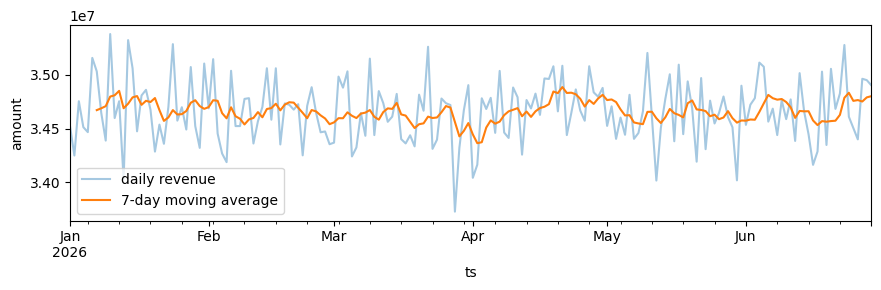

In [26]:
# Rolling window: daily revenue and its 7-day moving average
daily = sales.groupby(sales["ts"].dt.floor("D"))["amount"].sum().sort_index()
daily_7d = daily.rolling(7).mean()

ax = daily.to_pandas().plot(figsize=(9, 3), alpha=0.4, label="daily revenue")
daily_7d.to_pandas().plot(ax=ax, label="7-day moving average")
ax.set_ylabel("amount"); ax.legend(); plt.tight_layout(); plt.show()

In [27]:
# Rolling inside groups: average of each customer's last 3 orders
sales.groupby("customer_id")["amount"].rolling(3).mean().head(8)

customer_id   
0            0           <NA>
             1           <NA>
             2    1458.193333
             3    1108.463333
             4    1358.833333
             5    1233.433333
             6    1215.063333
             7         432.71
Name: amount, dtype: float64

In [28]:
by_cust_pd = sales_pd.groupby("customer_id")
compare("groupby cumsum",     lambda: by_cust_pd["amount"].cumsum(),   lambda: by_cust["amount"].cumsum())
compare("groupby shift",      lambda: by_cust_pd["amount"].shift(1),   lambda: by_cust["amount"].shift(1))
compare("groupby rank",
        lambda: sales_pd.groupby("category")["amount"].rank(method="dense", ascending=False),
        lambda: sales.groupby("category")["amount"].rank(method="dense", ascending=False))
compare("groupby rolling(3) mean",
        lambda: by_cust_pd["amount"].rolling(3).mean(),
        lambda: by_cust["amount"].rolling(3).mean(), repeats=1)

groupby cumsum                 pandas      48.0 ms | cuDF     29.5 ms |    1.6x
groupby shift                  pandas      95.8 ms | cuDF     27.2 ms |    3.5x
groupby rank                   pandas    1856.5 ms | cuDF    224.7 ms |    8.3x
groupby rolling(3) mean        pandas    7304.5 ms | cuDF     37.3 ms |  195.7x


## 7. One pipeline, two libraries

Because the APIs match, the same function runs on a pandas or a cuDF DataFrame. Question: **top 3 products per category by revenue in March**.

In [29]:
def top_products(df, month=3, n=3):
    m = df[df["ts"].dt.month == month]
    rev = m.groupby(["category", "product_name"], as_index=False)["amount"].sum()
    rev["rank"] = rev.groupby("category")["amount"].rank(method="first", ascending=False)
    return rev[rev["rank"] <= n].sort_values(["category", "rank"]).reset_index(drop=True)

top_products(sales)

,category,product_name,amount,rank
0,Books,BOOK-1144 Blue M,1086896.88,1.0
1,Books,BOOK-1822 Red XL,1071230.40,2.0
2,Books,BOOK-1089 Black M,1068416.36,3.0
3,Clothing,CLOT-0530 Blue S,1154422.50,1.0
4,Clothing,CLOT-1132 Blue S,1131924.10,2.0
5,Clothing,CLOT-1671 White L,1103234.64,3.0
6,Electronics,ELEC-1649 White S,1143464.94,1.0
7,Electronics,ELEC-0073 Black S,1130289.84,2.0
8,Electronics,ELEC-0736 Black L,1117201.80,3.0
9,Grocery,GROC-0782 White S,1099503.90,1.0


In [30]:
same = np.allclose(top_products(sales)["amount"].to_numpy(), top_products(sales_pd)["amount"].to_numpy())
print("same result as pandas:", same)
compare("pipeline: top 3 per category", lambda: top_products(sales_pd), lambda: top_products(sales))

same result as pandas: True
pipeline: top 3 per category   pandas     404.3 ms | cuDF     35.7 ms |   11.3x


## 8. Timing summary

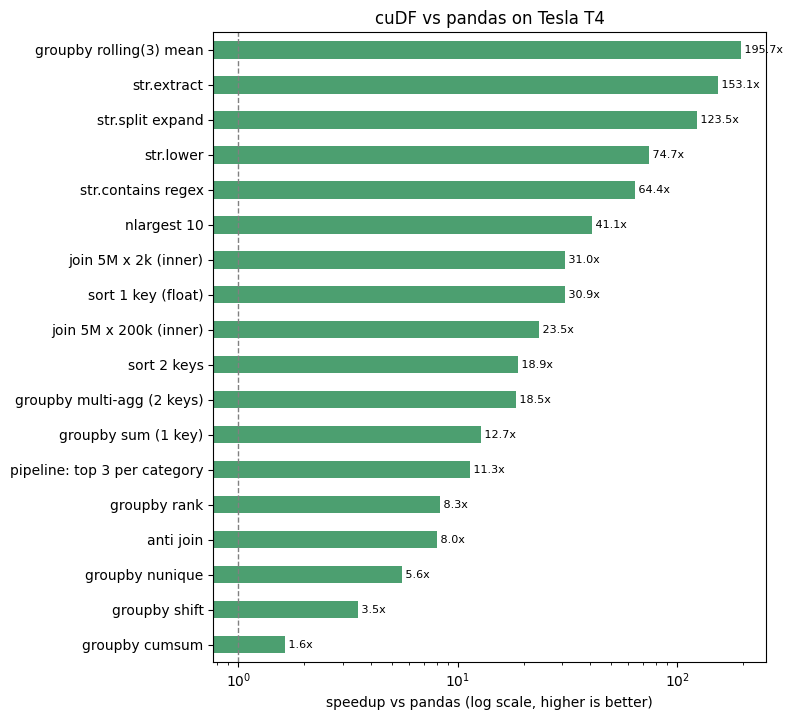

,pandas_s,cudf_s,speedup
groupby cumsum,0.0480,0.0295,1.6271
groupby shift,0.0958,0.0272,3.5258
groupby nunique,0.7276,0.1305,5.5769
anti join,0.0268,0.0033,8.0156
groupby rank,1.8565,0.2247,8.2623
pipeline: top 3 per category,0.4043,0.0357,11.3110
groupby sum (1 key),0.1031,0.0081,12.7393
groupby multi-agg (2 keys),0.3468,0.0187,18.5068
sort 2 keys,3.9847,0.2110,18.8830
join 5M x 200k (inner),1.2089,0.0515,23.4599


In [31]:
summary = pd.DataFrame(timings, index=["pandas_s", "cudf_s"]).T
summary["speedup"] = summary["pandas_s"] / summary["cudf_s"]
summary = summary.sort_values("speedup")

ax = summary["speedup"].plot.barh(figsize=(8, 0.35 * len(summary) + 1), color="#4C9F70")
ax.axvline(1, color="gray", lw=1, ls="--")
ax.set_xscale("log")
ax.set_xlabel("speedup vs pandas (log scale, higher is better)")
ax.set_title(f"cuDF vs pandas on {props['name'].decode()}")
for i, v in enumerate(summary["speedup"]):
    ax.text(v, i, f" {v:.1f}x", va="center", fontsize=8)
plt.tight_layout(); plt.show()

summary.round(4)

In [32]:
import gc
del orders_pd, customers_pd, products_pd, sales_pd, by_cust_pd
gc.collect()
free_b, total_b = cp.cuda.runtime.memGetInfo()
print(f"GPU memory used: {(total_b - free_b) / 1e9:.2f} GB / {total_b / 1e9:.1f} GB")

GPU memory used: 3.34 GB / 15.6 GB


## Summary

- **GroupBy**: `.agg({...})`, multiple keys, `nunique` and `transform` work as in pandas.
- **Joins**: same `merge` API, plus `leftsemi` / `leftanti`. Output row order is not guaranteed; sort if it matters.
- **Sorting**: `sort_values` with mixed directions and `nlargest` for top-N.
- **Strings**: regex `contains`, `extract`, `replace` and `split(expand=True)` all run on the GPU. This is often the biggest speedup.
- **Windows**: `cumcount`, `cumsum`, `shift`, `rank` and `rolling` inside `groupby`.
- The same function can run on pandas or cuDF: that idea is taken all the way in the next notebook.

**Try it:** set `N_ORDERS = 20_000_000` and rerun. Which operations gain the most?

**Next:** `03_cudf_pandas_accelerator.ipynb` — run unchanged pandas code on the GPU with `cudf.pandas`.